# STAT 404 Project — Search Algorithms and Maze Structure on Pathfinding Efficiency
**Group:** Naufal Prasojo, Chriscenci Susanto, Firila Najma Wahidah, Reyhan Pamungkas · Lab L1B

Analysis follows the proposal: a **split-plot design** with blocking.

| Stratum | Unit | Factors | Error term |
|---|---|---|---|
| Whole plot | maze (270) | Generation method *G* (block, 3), Size *S* (3), Loop density *D* (3) | maze-to-maze error (δ) |
| Subplot | one algorithm run on a maze (1350) | Algorithm *A* (5), *A×S*, *A×D* | run-level error (ε) |

Model (proposal, with the whole-plot error made explicit):

$$Y_{ijklm} = \mu + G_l + S_i + D_j + (SD)_{ij} + \delta_{m(ijl)} + A_k + (AS)_{ik} + (AD)_{jk} + \varepsilon_{ijklm}$$

with $\delta \sim N(0,\sigma^2_\delta)$ (maze effect) and $\varepsilon \sim N(0,\sigma^2)$. Three-way and higher interactions are pooled into ε.
Whole-plot effects are tested against MS(maze), subplot effects against MS(ε).

Responses: `time_s` and `nodes_explored`, analysed on the log scale (both span ~3 orders of magnitude).

In [8]:
suppressPackageStartupMessages({
  library(MASS)      # boxcox (load before dplyr so select() isn't masked)
  library(dplyr); library(tidyr); library(ggplot2)
  library(lme4); library(car); library(patchwork)
})
options(repr.plot.width = 15, repr.plot.height = 4.5, width = 180, digits = 5)
theme_set(theme_bw(base_size = 12))

ALG_LEVELS <- c("bfs", "dijkstra", "astar", "greedy", "random_walk")
df <- read.csv("results_1.csv") %>%
  mutate(A    = factor(algorithm, levels = ALG_LEVELS),
         G    = factor(gen_method),
         S    = factor(size, levels = c(20, 50, 100)),
         D    = factor(loop_density, levels = c(0.05, 0.15, 0.30)),
         maze = factor(maze_id),
         log_time  = log(time_s),
         log_nodes = log(nodes_explored))
cat(dim(df), "| mazes:", nlevels(df$maze), "\n")
head(df)

Warning message:
"package 'car' was built under R version 4.4.3"
Warning message:
"package 'carData' was built under R version 4.4.3"
Warning message:
"package 'patchwork' was built under R version 4.4.3"


1350 24 | mazes: 270 


,maze_id,seed,gen_method,size,loop_density,rep,loops_added,opt_path_length,alg_order,run_position,⋯,success,path_length,gen_time_s,A,G,S,D,maze,log_time,log_nodes
,<int>,<dbl>,<chr>,<int>,<dbl>,<int>,<int>,<int>,<chr>,<int>,⋯,<int>,<int>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>
1,1,1876670030,dfs,100,0.30,10,2940,198,bfs-greedy-random_walk-dijkstra-astar,1,⋯,1,198,0.037822,bfs,dfs,100,0.3,1,-5.3388,9.2102
2,1,1876670030,dfs,100,0.30,10,2940,198,bfs-greedy-random_walk-dijkstra-astar,2,⋯,1,254,0.037822,greedy,dfs,100,0.3,1,-8.1814,5.6870
3,1,1876670030,dfs,100,0.30,10,2940,198,bfs-greedy-random_walk-dijkstra-astar,3,⋯,1,40836,0.037822,random_walk,dfs,100,0.3,1,-4.3026,8.2610
4,1,1876670030,dfs,100,0.30,10,2940,198,bfs-greedy-random_walk-dijkstra-astar,4,⋯,1,198,0.037822,dijkstra,dfs,100,0.3,1,-4.9926,9.2102
5,1,1876670030,dfs,100,0.30,10,2940,198,bfs-greedy-random_walk-dijkstra-astar,5,⋯,1,198,0.037822,astar,dfs,100,0.3,1,-6.3038,7.3846
6,2,2702459816,kruskal,100,0.05,5,490,254,bfs-astar-greedy-dijkstra-random_walk,1,⋯,1,254,0.040394,bfs,kruskal,100,0.05,2,-5.6193,9.2100


## 1. Design check

In [9]:
cat("Mazes per G x S x D cell:\n")
ftable(xtabs(~ G + S + D, data = distinct(df, maze_id, G, S, D)))
cat("Each algorithm appears exactly once per maze:", all(table(df$maze, df$A) == 1), "\n")
cat("\nRun-position balance (randomization check):\n")
table(df$A, df$run_position)

Mazes per G x S x D cell:


            D 0.05 0.15 0.3
G       S                  
dfs     20      10   10  10
        50      10   10  10
        100     10   10  10
kruskal 20      10   10  10
        50      10   10  10
        100     10   10  10
prim    20      10   10  10
        50      10   10  10
        100     10   10  10

Each algorithm appears exactly once per maze: TRUE 

Run-position balance (randomization check):


             
               1  2  3  4  5
  bfs         51 60 57 47 55
  dijkstra    53 59 41 68 49
  astar       46 49 60 51 64
  greedy      60 50 56 53 51
  random_walk 60 52 56 51 51

### Success rate
Random walk failed on 4 runs (all 100×100, 5% loops) by hitting the 2,000,000-step cap, so their time / nodes are **right-censored**.
They're kept in the main analysis (dropping them would make the design unbalanced and bias RW downward); Section 8 reruns without them as a sensitivity check.

In [10]:
df %>% group_by(A) %>% summarise(success_rate = mean(success), failures = sum(success == 0), n = n())
df %>% filter(success == 0) %>% select(maze_id, G, S, D, algorithm, time_s, nodes_explored, steps)

A,success_rate,failures,n
<fct>,<dbl>,<int>,<int>
bfs,1.00000,0,270
dijkstra,1.00000,0,270
astar,1.00000,0,270
greedy,1.00000,0,270
random_walk,0.98519,4,270


maze_id,G,S,D,algorithm,time_s,nodes_explored,steps
<int>,<fct>,<fct>,<fct>,<chr>,<dbl>,<int>,<int>
58,kruskal,100,0.05,random_walk,0.80577,9677,2000000
74,dfs,100,0.05,random_walk,0.57024,9655,2000000
149,dfs,100,0.05,random_walk,0.75379,9110,2000000
203,dfs,100,0.05,random_walk,0.70757,9242,2000000


## 2. Descriptive summaries

In [11]:
df %>% group_by(A) %>%
  summarise(time_med = median(time_s), time_mean = mean(time_s),
            nodes_med = median(nodes_explored), nodes_mean = mean(nodes_explored),
            path_len_med = median(path_length), opt_path_med = median(opt_path_length))

A,time_med,time_mean,nodes_med,nodes_mean,path_len_med,opt_path_med
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
bfs,0.00076780,0.00182227,2498.0,4271.05,105,105
dijkstra,0.00201320,0.00439323,2499.0,4272.59,105,105
astar,0.00136185,0.00304840,1077.5,2011.83,105,105
greedy,0.00024365,0.00036842,196.5,267.03,130,105
random_walk,0.01750470,0.06990585,1886.0,3241.57,38861,105


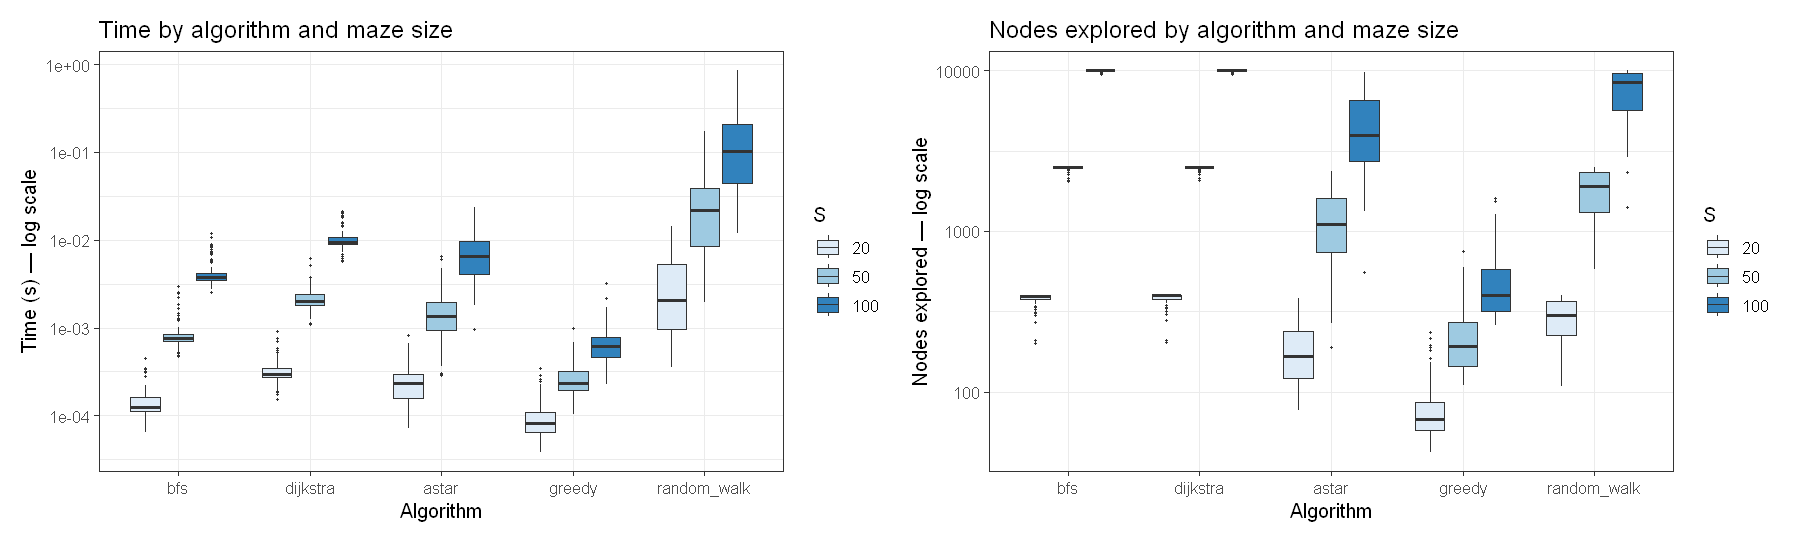

In [12]:
p1 <- ggplot(df, aes(A, time_s, fill = S)) + geom_boxplot(outlier.size = .6) +
  scale_y_log10() + scale_fill_brewer(palette = "Blues") +
  labs(x = "Algorithm", y = "Time (s) — log scale", title = "Time by algorithm and maze size")
p2 <- ggplot(df, aes(A, nodes_explored, fill = S)) + geom_boxplot(outlier.size = .6) +
  scale_y_log10() + scale_fill_brewer(palette = "Blues") +
  labs(x = "Algorithm", y = "Nodes explored — log scale", title = "Nodes explored by algorithm and maze size")
p1 + p2

Note: on an unweighted grid Dijkstra and BFS expand essentially the same nodes (same frontier order up to ties), so their node counts are nearly identical; they differ mainly in time (priority-queue overhead).

## 3. Split-plot ANOVA
Fitted with `aov(... + Error(maze))`, which splits the analysis into the two strata automatically:
- **`Error: maze`** = whole-plot stratum (G, S, D, S×D vs maze-to-maze error)
- **`Error: Within`** = subplot stratum (A, A×S, A×D vs run-level error)

In [13]:
split_plot <- function(data, y, sub = "A + A:S + A:D") {
  f   <- as.formula(paste(y, "~ G + S*D +", sub, "+ Error(maze)"))
  fit <- aov(f, data = data)
  s   <- summary(fit)
  wp  <- s[["Error: maze"]][[1]];  sp <- s[["Error: Within"]][[1]]
  mk  <- function(t, stratum) data.frame(Stratum = stratum, Term = trimws(rownames(t)),
                                         t, check.names = FALSE, row.names = NULL)
  tab <- rbind(mk(wp, "Whole plot"), mk(sp, "Subplot"))
  tab$Term[tab$Term == "Residuals"] <- c("Whole-plot error [maze(G,S,D)]", "Subplot error")
  tab$Term[tab$Term == "G"] <- "G (block)"
  tab$pct_SS <- 100 * tab$`Sum Sq` / sum(tab$`Sum Sq`)
  r_wp <- nrow(wp); r_sp <- nrow(sp)
  list(fit = fit, tab = tab,
       ms_wp = wp[r_wp, "Mean Sq"], df_wp = wp[r_wp, "Df"],
       ms_sp = sp[r_sp, "Mean Sq"], df_sp = sp[r_sp, "Df"])
}

res <- list()
for (y in c("log_time", "log_nodes")) {
  res[[y]] <- split_plot(df, y)
  cat("\n=====", y, "=====\n"); print(res[[y]]$tab, digits = 4)
}


===== log_time =====
     Stratum                           Term   Df   Sum Sq   Mean Sq  F value     Pr(>F)   pct_SS
1 Whole plot                      G (block)    2    1.996    0.9979    1.547  2.149e-01  0.03632
2 Whole plot                              S    2 2347.068 1173.5341 1818.996 3.333e-153 42.71756
3 Whole plot                              D    2   15.765    7.8824   12.218  8.500e-06  0.28693
4 Whole plot                            S:D    4    7.110    1.7775    2.755  2.849e-02  0.12940
5 Whole plot Whole-plot error [maze(G,S,D)]  259  167.095    0.6452       NA         NA  3.04120
6    Subplot                              A    4 2566.940  641.7349 2687.875  0.000e+00 46.71931
7    Subplot                            S:A    8   95.043   11.8804   49.760  2.100e-68  1.72982
8    Subplot                            D:A    8   40.294    5.0368   21.096  6.627e-30  0.73337
9    Subplot                  Subplot error 1060  253.077    0.2388       NA         NA  4.60610

===== l

In [14]:
# sanity check: SS from both strata add up to the corrected total SS
for (y in names(res)) cat(y, sum(res[[y]]$tab$`Sum Sq`), sum((df[[y]] - mean(df[[y]]))^2), "\n")

log_time 5494.4 5494.4 
log_nodes 3296.8 3296.8 


### Mixed-model cross-check (REML)
Same model fitted with `lmer` and a random maze intercept. Gives the variance components directly.

In [15]:
vc <- lapply(names(res), function(y) {
  m  <- lmer(as.formula(paste(y, "~ G + S*D + A + A:S + A:D + (1 | maze)")), data = df, REML = TRUE)
  res[[y]]$lmer <<- m
  v  <- as.data.frame(VarCorr(m))$vcov
  data.frame(response = y, sigma2_maze = v[1], sigma2_error = v[2], ICC = v[1] / sum(v))
})
do.call(rbind, vc)

response,sigma2_maze,sigma2_error,ICC
<chr>,<dbl>,<dbl>,<dbl>
log_time,0.0812807,0.238752,0.25398
log_nodes,0.0074448,0.082079,0.08316


### Share of variation: maze vs algorithm (Objective 3)
From the ANOVA sums of squares: everything in the whole-plot stratum is "maze" (structure + maze-to-maze noise); the algorithm main effect and its interactions are "algorithm".

response,Maze_total,Maze_structure_SDG,Maze_error,Algorithm_main,Algorithm_x_structure,Subplot_error
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
log_time,46.211,43.170,3.04120,46.719,2.4632,4.6061
log_nodes,61.020,60.083,0.93727,33.315,3.0257,2.6391


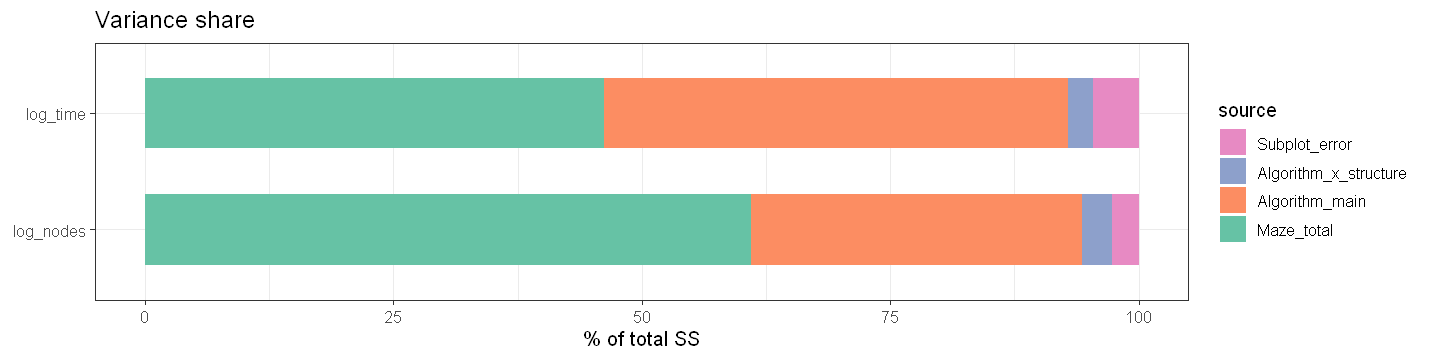

In [16]:
share <- do.call(rbind, lapply(names(res), function(y) {
  t <- res[[y]]$tab; tot <- sum(t$`Sum Sq`); ss <- setNames(t$`Sum Sq`, t$Term)
  data.frame(response = y,
             Maze_total            = 100 * sum(t$`Sum Sq`[t$Stratum == "Whole plot"]) / tot,
             Maze_structure_SDG    = 100 * sum(ss[c("G (block)", "S", "D", "S:D")]) / tot,
             Maze_error            = 100 * ss["Whole-plot error [maze(G,S,D)]"] / tot,
             Algorithm_main        = 100 * ss["A"] / tot,
             Algorithm_x_structure = 100 * sum(ss[c("S:A", "D:A")]) / tot,
             Subplot_error         = 100 * ss["Subplot error"] / tot, row.names = NULL)
}))
share

options(repr.plot.width = 12, repr.plot.height = 3)
share %>% select(response, Maze_total, Algorithm_main, Algorithm_x_structure, Subplot_error) %>%
  pivot_longer(-response, names_to = "source", values_to = "pct") %>%
  mutate(source = factor(source, levels = rev(c("Maze_total", "Algorithm_main", "Algorithm_x_structure", "Subplot_error")))) %>%
  ggplot(aes(pct, response, fill = source)) + geom_col(width = .6) +
  scale_fill_brewer(palette = "Set2", direction = -1) + labs(x = "% of total SS", y = NULL, title = "Variance share")
options(repr.plot.width = 15, repr.plot.height = 4.5)

## 4. Whole-plot analysis (maze level)
Each point is a maze mean over the 5 algorithms. These plots show the effects tested against the whole-plot error.

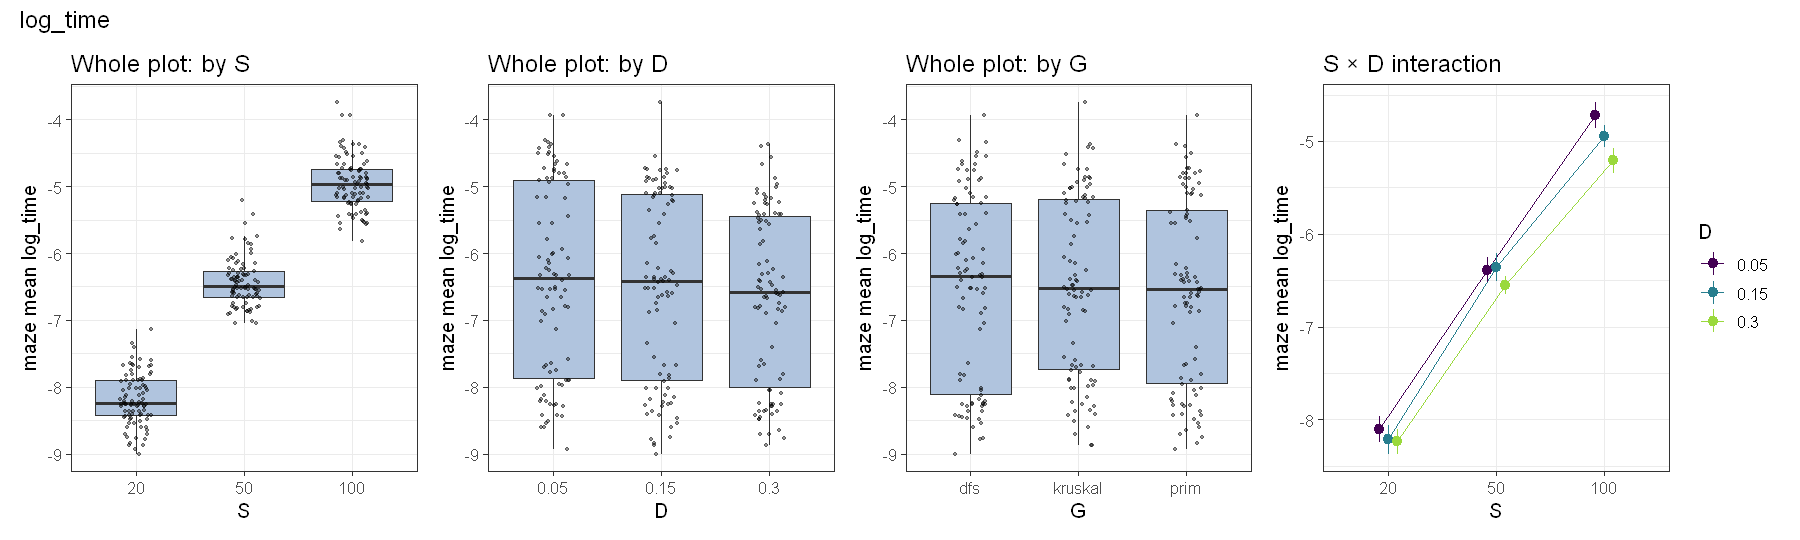

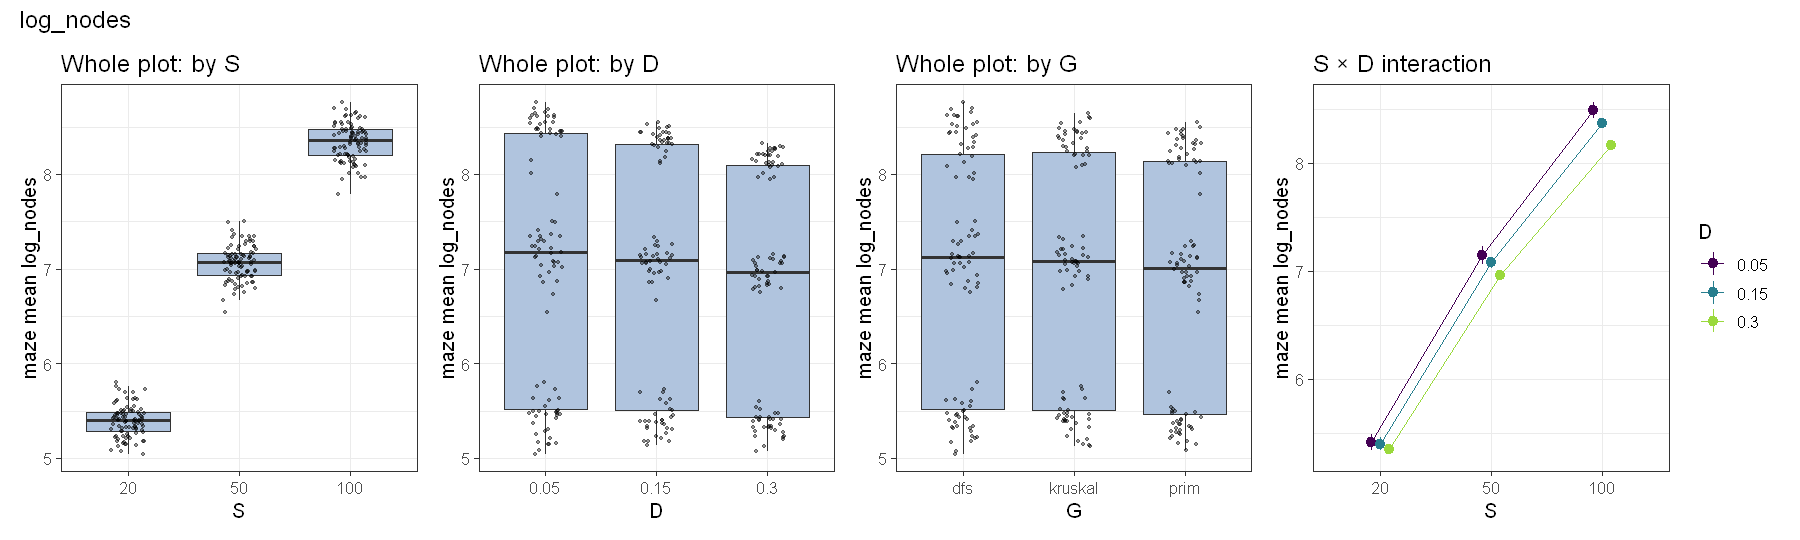

In [17]:
wp <- df %>% group_by(maze_id, G, S, D) %>%
  summarise(log_time = mean(log_time), log_nodes = mean(log_nodes), .groups = "drop")
ci95 <- function(x) { m <- mean(x); h <- qt(.975, length(x) - 1) * sd(x) / sqrt(length(x))
                      data.frame(y = m, ymin = m - h, ymax = m + h) }

for (y in c("log_time", "log_nodes")) {
  box_by <- function(f) ggplot(wp, aes(.data[[f]], .data[[y]])) +
    geom_boxplot(fill = "lightsteelblue", outlier.shape = NA) +
    geom_jitter(width = .15, size = .8, alpha = .4) +
    labs(x = f, y = paste("maze mean", y), title = paste("Whole plot: by", f))
  sd_plot <- ggplot(wp, aes(S, .data[[y]], colour = D, group = D)) +
    stat_summary(fun = mean, geom = "line", position = position_dodge(.25)) +
    stat_summary(fun.data = ci95, geom = "pointrange", position = position_dodge(.25)) +
    scale_colour_viridis_d(end = .85) + labs(y = paste("maze mean", y), title = "S × D interaction")
  print(box_by("S") + box_by("D") + box_by("G") + sd_plot + plot_layout(nrow = 1) +
        plot_annotation(title = y))
}

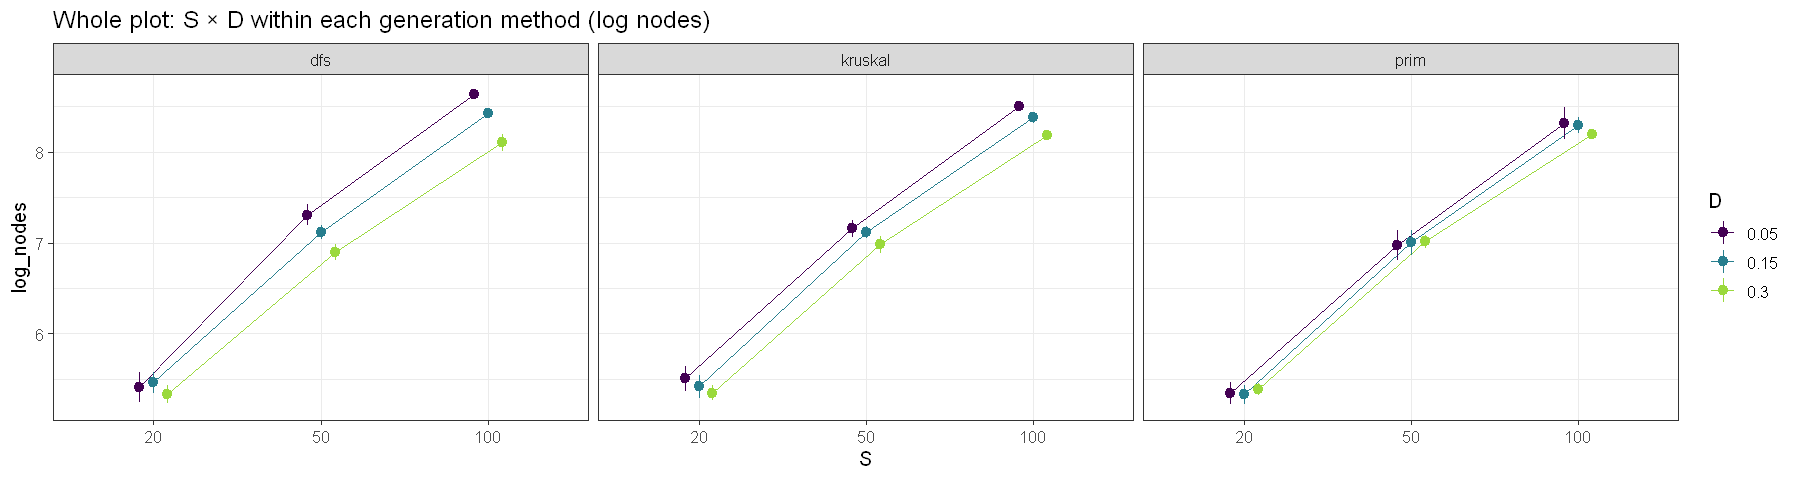

In [18]:
# S x D within each block (G)
options(repr.plot.height = 4)
ggplot(wp, aes(S, log_nodes, colour = D, group = D)) +
  stat_summary(fun = mean, geom = "line", position = position_dodge(.25)) +
  stat_summary(fun.data = ci95, geom = "pointrange", position = position_dodge(.25)) +
  facet_wrap(~ G) + scale_colour_viridis_d(end = .85) +
  labs(title = "Whole plot: S × D within each generation method (log nodes)")
options(repr.plot.height = 4.5)

### Whole-plot trend contrasts (linear / quadratic in S and D)
Orthogonal polynomials from `contr.poly()` using the actual (unequally spaced) level values; tested with the whole-plot error.

In [19]:
wp_trends <- function(y) {
  m <- lm(as.formula(paste(y, "~ G + S*D")), data = wp)
  mse <- sigma(m)^2; dfe <- df.residual(m); tc <- qt(.975, dfe)
  out <- list()
  for (f in c("S", "D")) {
    lv    <- as.numeric(levels(wp[[f]]))
    means <- tapply(wp[[y]], wp[[f]], mean); n <- sum(wp[[f]] == levels(wp[[f]])[1])
    P     <- contr.poly(3, scores = lv)
    for (j in 1:2) {
      c <- P[, j]; est <- sum(c * means); se <- sqrt(mse * sum(c^2) / n); t <- est / se
      out[[length(out) + 1]] <- data.frame(factor = f, trend = c("linear", "quadratic")[j],
        coef = paste(round(c, 3), collapse = ", "), estimate = est, SE = se, t = t,
        p = 2 * pt(-abs(t), dfe), lo95 = est - tc * se, hi95 = est + tc * se)
    }
  }
  do.call(rbind, out)
}
for (y in names(res)) { cat("\n", y, "\n"); print(wp_trends(y), digits = 4) }


 log_time 
  factor     trend                  coef  estimate      SE        t          p     lo95     hi95
1      S    linear -0.642, -0.117, 0.758  2.241553 0.03786  59.2002 1.552e-152  2.16699  2.31611
2      S quadratic  0.505, -0.808, 0.303 -0.437203 0.03786 -11.5467  3.725e-25 -0.51176 -0.36264
3      D    linear -0.656, -0.094, 0.749 -0.187163 0.03786  -4.9430  1.383e-06 -0.26172 -0.11260
4      D quadratic  0.487, -0.811, 0.324 -0.001749 0.03786  -0.0462  9.632e-01 -0.07631  0.07281

 log_nodes 
  factor     trend                  coef  estimate      SE        t          p     lo95     hi95
1      S    linear -0.642, -0.117, 0.758  2.040347 0.01628 125.3094 8.372e-234  2.00828  2.07241
2      S quadratic  0.505, -0.808, 0.303 -0.457559 0.01628 -28.1014  1.272e-80 -0.48962 -0.42550
3      D    linear -0.656, -0.094, 0.749 -0.136068 0.01628  -8.3567  3.972e-15 -0.16813 -0.10401
4      D quadratic  0.487, -0.811, 0.324 -0.007045 0.01628  -0.4327  6.656e-01 -0.03911  0.02502


### Estimated whole-plot means (95% CI, whole-plot error)
`geo_*` columns are back-transformed (geometric means).

In [20]:
wp_means <- function(y) {
  m <- lm(as.formula(paste(y, "~ G + S*D")), data = wp); tc <- qt(.975, df.residual(m))
  do.call(rbind, lapply(c("S", "D", "G"), function(f) {
    wp %>% group_by(level = .data[[f]]) %>%
      summarise(mean_log = mean(.data[[y]]), n = n(), .groups = "drop") %>%
      mutate(factor = f, se = sigma(m) / sqrt(n), lo = mean_log - tc * se, hi = mean_log + tc * se,
             geo_mean = exp(mean_log), geo_lo = exp(lo), geo_hi = exp(hi), level = as.character(level)) %>%
      select(factor, level, mean_log, lo, hi, geo_mean, geo_lo, geo_hi)
  }))
}
for (y in names(res)) { cat("\n", y, "\n"); print(as.data.frame(wp_means(y)), digits = 4) }


 log_time 
  factor   level mean_log     lo     hi geo_mean   geo_lo    geo_hi
1      S      20   -8.184 -8.259 -8.110 0.000279 0.000259 0.0003006
2      S      50   -6.434 -6.508 -6.359 0.001607 0.001491 0.0017311
3      S     100   -4.958 -5.033 -4.884 0.007024 0.006519 0.0075679
4      D    0.05   -6.404 -6.478 -6.329 0.001656 0.001537 0.0017838
5      D    0.15   -6.506 -6.581 -6.432 0.001494 0.001386 0.0016094
6      D     0.3   -6.666 -6.741 -6.592 0.001273 0.001182 0.0013718
7      G     dfs   -6.517 -6.591 -6.442 0.001478 0.001372 0.0015927
8      G kruskal   -6.483 -6.558 -6.409 0.001529 0.001419 0.0016473
9      G    prim   -6.576 -6.651 -6.502 0.001393 0.001293 0.0015010

 log_nodes 
  factor   level mean_log    lo    hi geo_mean geo_lo geo_hi
1      S      20    5.391 5.359 5.423    219.4  212.5  226.6
2      S      50    7.063 7.031 7.095   1167.7 1130.9 1205.8
3      S     100    8.339 8.307 8.371   4185.2 4053.2 4321.6
4      D    0.05    7.017 6.985 7.049   1115.2 1080

## 5. Subplot analysis (algorithm within maze)
Algorithm and its interactions with maze structure, tested against the subplot error.

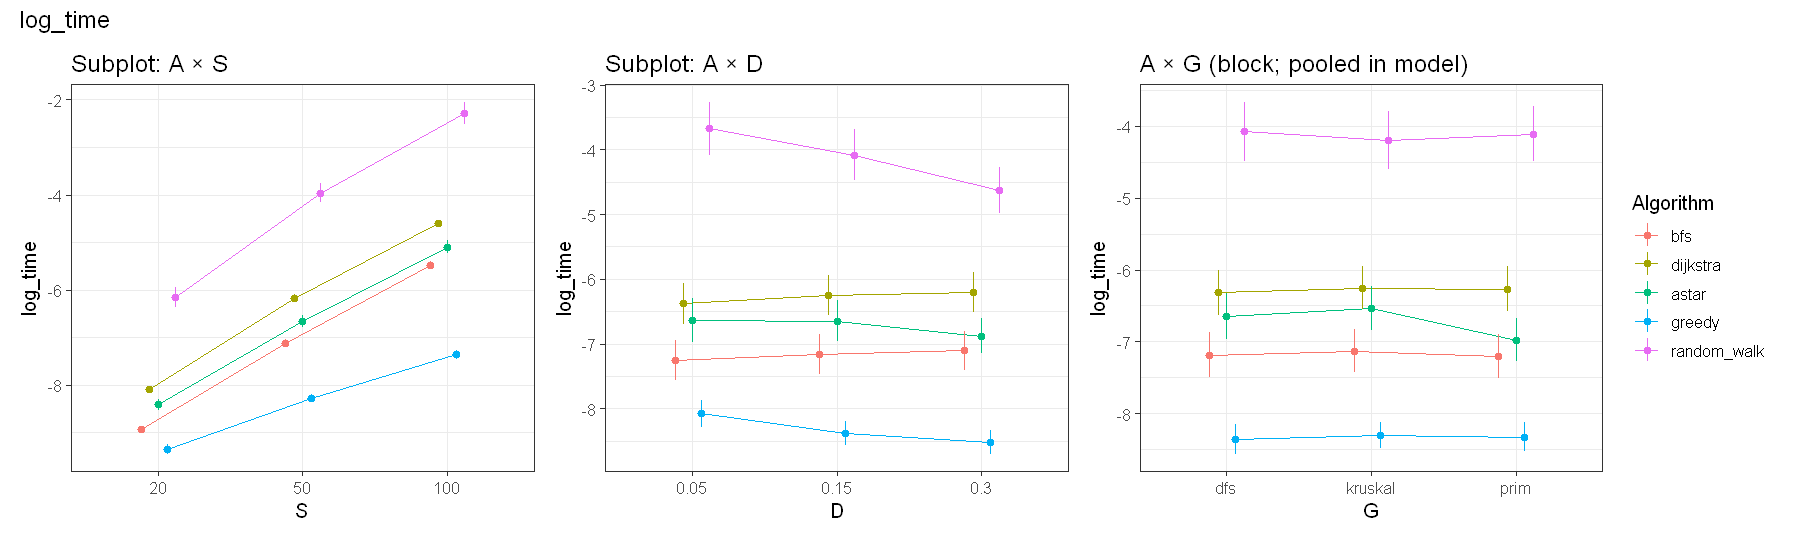

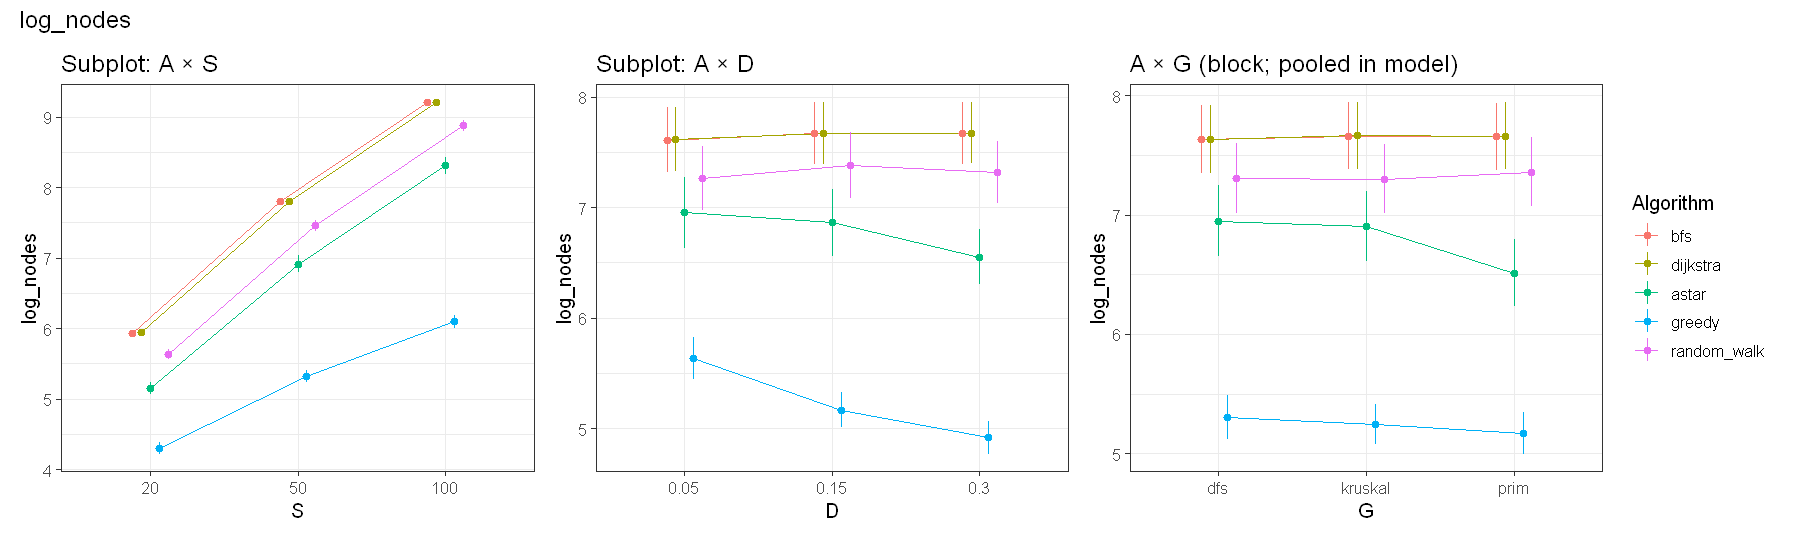

In [21]:
int_plot <- function(y, f, ttl) ggplot(df, aes(.data[[f]], .data[[y]], colour = A, group = A)) +
  stat_summary(fun = mean, geom = "line", position = position_dodge(.3)) +
  stat_summary(fun.data = ci95, geom = "pointrange", size = .3, position = position_dodge(.3)) +
  labs(title = ttl, colour = "Algorithm")
for (y in c("log_time", "log_nodes"))
  print(int_plot(y, "S", "Subplot: A × S") + int_plot(y, "D", "Subplot: A × D") +
        int_plot(y, "G", "A × G (block; pooled in model)") +
        plot_layout(guides = "collect") + plot_annotation(title = y))

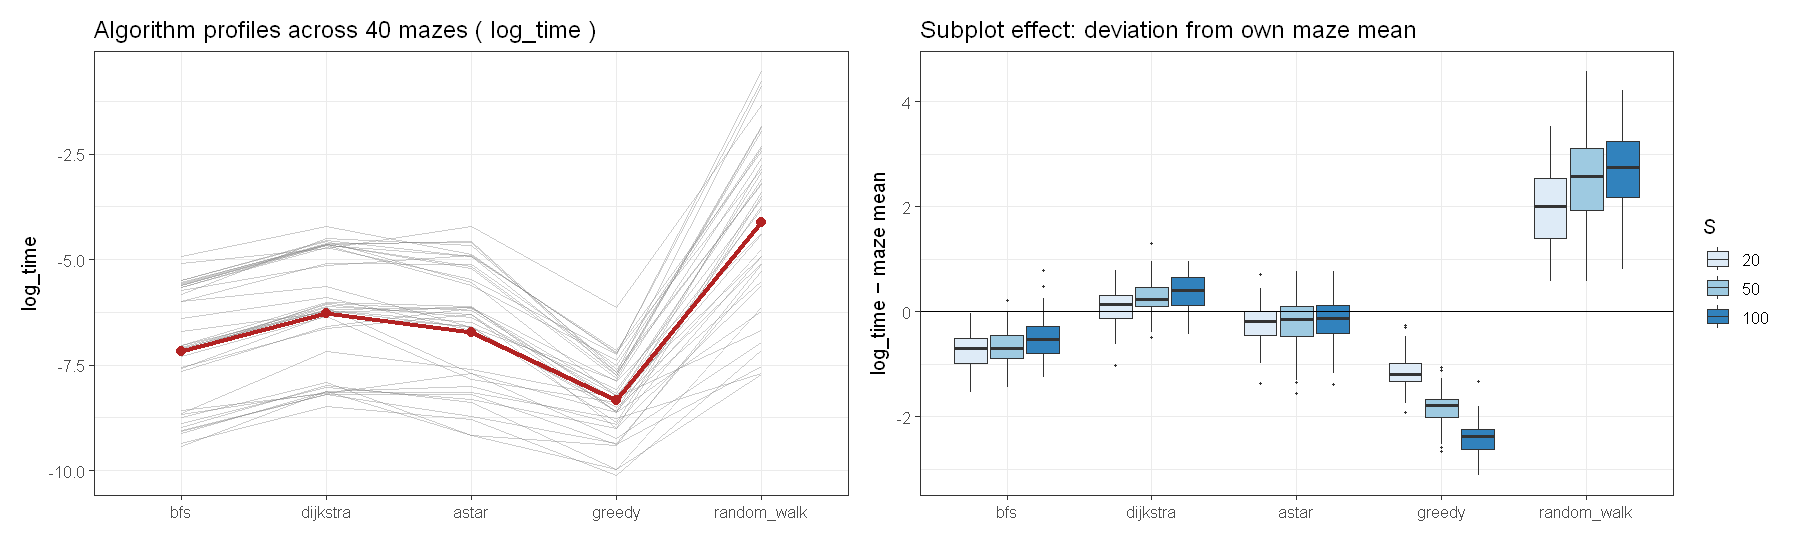

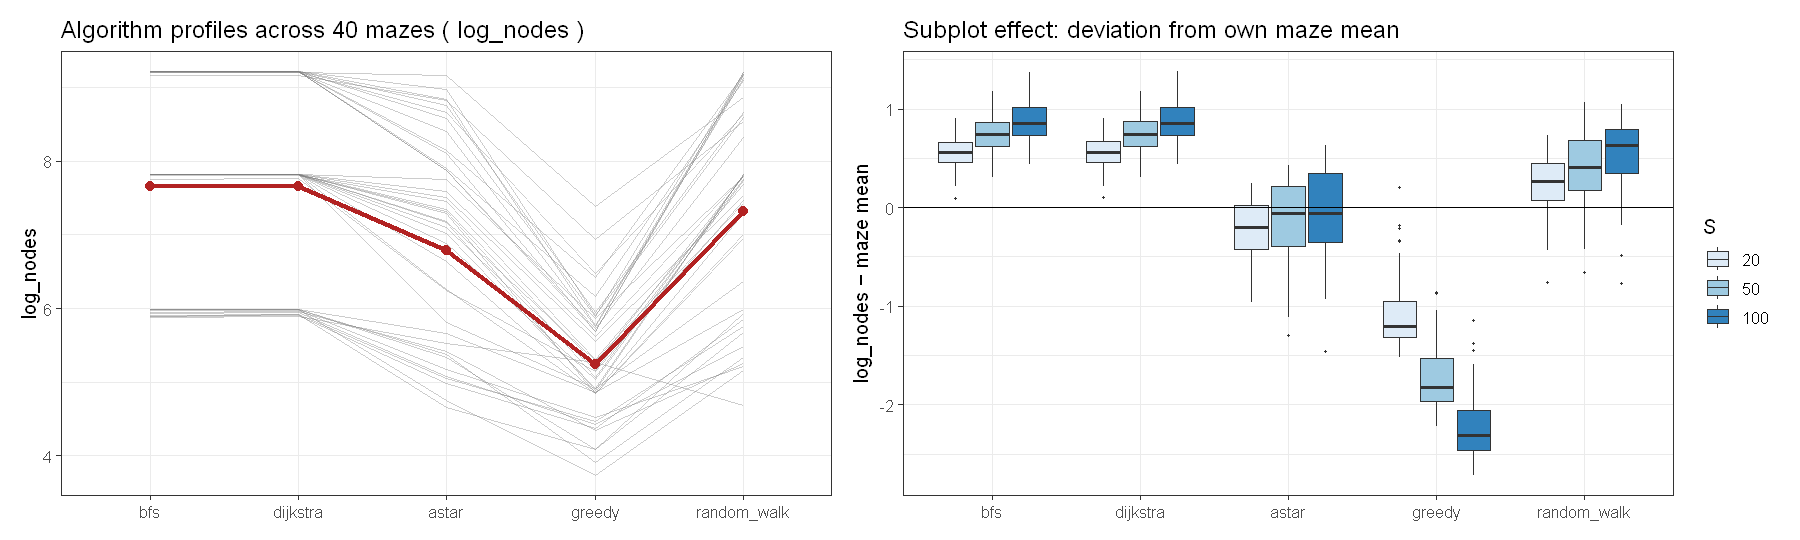

In [22]:
# Within-maze algorithm effects: subtract each maze's mean -> removes all whole-plot variation
set.seed(1); sample_mazes <- sample(unique(df$maze_id), 40)
for (y in c("log_time", "log_nodes")) {
  d <- df %>% group_by(maze_id) %>% mutate(within = .data[[y]] - mean(.data[[y]])) %>% ungroup()
  overall <- df %>% group_by(A) %>% summarise(m = mean(.data[[y]]))
  pa <- ggplot(filter(d, maze_id %in% sample_mazes), aes(A, .data[[y]], group = maze_id)) +
    geom_line(colour = "grey50", alpha = .4) +
    geom_line(data = overall, aes(A, m, group = 1), colour = "firebrick", linewidth = 1.3, inherit.aes = FALSE) +
    geom_point(data = overall, aes(A, m), colour = "firebrick", size = 2.5, inherit.aes = FALSE) +
    labs(title = paste("Algorithm profiles across 40 mazes (", y, ")"), x = NULL)
  pb <- ggplot(d, aes(A, within, fill = S)) + geom_boxplot(outlier.size = .5) +
    geom_hline(yintercept = 0) + scale_fill_brewer(palette = "Blues") +
    labs(y = paste(y, "− maze mean"), title = "Subplot effect: deviation from own maze mean", x = NULL)
  print(pa + pb)
}

In [23]:
# Share of mazes where each algorithm is best (rank 1), by S and D. Does the winner change?
for (y in c("log_time", "log_nodes")) {
  cat("\n", y, "\n")
  df %>% group_by(maze_id) %>% mutate(best = rank(.data[[y]]) == 1) %>%
    group_by(S, D, A) %>% summarise(p_best = mean(best), .groups = "drop") %>%
    pivot_wider(names_from = A, values_from = p_best) %>% as.data.frame() %>% print(digits = 2)
}


 log_time 
    S    D   bfs dijkstra astar greedy random_walk
1  20 0.05 0.233        0 0.033   0.73           0
2  20 0.15 0.167        0 0.000   0.83           0
3  20  0.3 0.067        0 0.000   0.93           0
4  50 0.05 0.000        0 0.033   0.97           0
5  50 0.15 0.000        0 0.000   1.00           0
6  50  0.3 0.000        0 0.000   1.00           0
7 100 0.05 0.000        0 0.000   1.00           0
8 100 0.15 0.000        0 0.000   1.00           0
9 100  0.3 0.000        0 0.000   1.00           0

 log_nodes 
    S    D bfs dijkstra astar greedy random_walk
1  20 0.05   0        0 0.100   0.87       0.033
2  20 0.15   0        0 0.033   0.97       0.000
3  20  0.3   0        0 0.000   1.00       0.000
4  50 0.05   0        0 0.000   1.00       0.000
5  50 0.15   0        0 0.000   1.00       0.000
6  50  0.3   0        0 0.000   1.00       0.000
7 100 0.05   0        0 0.000   1.00       0.000
8 100 0.15   0        0 0.000   1.00       0.000
9 100  0.3   0        0 

### Planned subplot contrasts (proposal)
Estimated on the log scale with the subplot error MS; `ratio` = exp(estimate), i.e. the multiplicative difference in geometric means.
- A* vs Dijkstra
- Informed (A*, Greedy) vs Uninformed (BFS, Dijkstra)
- Random walk vs the rest

In [24]:
contrasts_list <- list(
  "A* vs Dijkstra"         = c(bfs = 0,   dijkstra = -1,  astar = 1,   greedy = 0,   random_walk = 0),
  "Informed vs Uninformed" = c(bfs = -.5, dijkstra = -.5, astar = .5,  greedy = .5,  random_walk = 0),
  "Random walk vs rest"    = c(bfs = -.25, dijkstra = -.25, astar = -.25, greedy = -.25, random_walk = 1))

sub_contrasts <- function(y, by = NULL) {
  mse <- res[[y]]$ms_sp; dfe <- res[[y]]$df_sp; tc <- qt(.975, dfe)
  groups <- if (is.null(by)) list(all = df) else split(df, df[[by]])
  do.call(rbind, lapply(names(groups), function(g) {
    d <- groups[[g]]; means <- tapply(d[[y]], d$A, mean)[ALG_LEVELS]; n <- sum(d$A == "bfs")
    do.call(rbind, lapply(names(contrasts_list), function(nm) {
      c <- contrasts_list[[nm]][ALG_LEVELS]; est <- sum(c * means)
      se <- sqrt(mse * sum(c^2) / n); t <- est / se
      data.frame(level = g, contrast = nm, estimate = est, SE = se, t = t, p = 2 * pt(-abs(t), dfe),
                 lo95 = est - tc * se, hi95 = est + tc * se,
                 ratio = exp(est), ratio_lo = exp(est - tc * se), ratio_hi = exp(est + tc * se))
    }))
  }))
}
for (y in names(res)) { cat("\n", y, "\n"); print(sub_contrasts(y)[, -1], digits = 4) }


 log_time 
                contrast estimate      SE      t          p    lo95    hi95   ratio ratio_lo ratio_hi
1         A* vs Dijkstra  -0.4401 0.04205 -10.46  1.868e-24 -0.5226 -0.3575  0.6440   0.5930   0.6994
2 Informed vs Uninformed  -0.7970 0.02974 -26.80 3.150e-121 -0.8553 -0.7386  0.4507   0.4252   0.4778
3    Random walk vs rest   2.9955 0.03325  90.10  0.000e+00  2.9303  3.0608 19.9958  18.7330  21.3437

 log_nodes 
                contrast estimate      SE      t          p    lo95    hi95  ratio ratio_lo ratio_hi
1         A* vs Dijkstra  -0.8638 0.02466 -35.03 3.185e-179 -0.9122 -0.8154 0.4216   0.4016   0.4425
2 Informed vs Uninformed  -1.6368 0.01744 -93.88  0.000e+00 -1.6711 -1.6026 0.1946   0.1880   0.2014
3    Random walk vs rest   0.4884 0.01949  25.06 3.392e-109  0.4502  0.5267 1.6298   1.5686   1.6933


In [25]:
# Same contrasts within each maze size / loop density (ratio scale)
for (y in names(res)) for (by in c("S", "D")) {
  cat("\n", y, "— contrast ratios by", by, "\n")
  sub_contrasts(y, by) %>% select(level, contrast, ratio) %>%
    pivot_wider(names_from = level, values_from = ratio) %>% as.data.frame() %>% print(digits = 3)
}


 log_time — contrast ratios by S 
                contrast     20     50    100
1         A* vs Dijkstra  0.722  0.613  0.603
2 Informed vs Uninformed  0.690  0.439  0.302
3    Random walk vs rest 12.767 22.005 28.458

 log_time — contrast ratios by D 
                contrast   0.05   0.15    0.3
1         A* vs Dijkstra  0.776  0.674  0.511
2 Informed vs Uninformed  0.583  0.445  0.353
3    Random walk vs rest 30.247 20.671 12.787

 log_nodes — contrast ratios by S 
                contrast    20    50   100
1         A* vs Dijkstra 0.452 0.407 0.407
2 Informed vs Uninformed 0.297 0.184 0.135
3    Random walk vs rest 1.350 1.640 1.954

 log_nodes — contrast ratios by D 
                contrast  0.05  0.15   0.3
1         A* vs Dijkstra 0.516 0.447 0.325
2 Informed vs Uninformed 0.267 0.192 0.144
3    Random walk vs rest 1.368 1.714 1.846


### Estimated algorithm means and A × S cell means (95% CI)
Algorithm marginal means use the subplot error. A × S cell means compare across mazes, so their SE combines both strata:
$\mathrm{Var}(\bar y_{ik}) = \frac{MS_{wp} + (a-1)MS_{sp}}{a\,n}$, with Satterthwaite df.

In [26]:
alg_means <- function(y) {
  tc <- qt(.975, res[[y]]$df_sp)
  df %>% group_by(A) %>% summarise(mean_log = mean(.data[[y]]), n = n()) %>%
    mutate(se = sqrt(res[[y]]$ms_sp / n), lo = mean_log - tc * se, hi = mean_log + tc * se,
           geo_mean = exp(mean_log), geo_lo = exp(lo), geo_hi = exp(hi)) %>% select(-n, -se)
}
cell_means <- function(y, f = "S", a = 5) {
  r <- res[[y]]; num <- r$ms_wp + (a - 1) * r$ms_sp
  nu <- num^2 / (r$ms_wp^2 / r$df_wp + ((a - 1) * r$ms_sp)^2 / r$df_sp)
  out <- df %>% group_by(level = .data[[f]], A) %>% summarise(mean_log = mean(.data[[y]]), n = n(), .groups = "drop") %>%
    mutate(se = sqrt(num / (a * n)), lo = mean_log - qt(.975, nu) * se, hi = mean_log + qt(.975, nu) * se,
           geo_mean = exp(mean_log))
  attr(out, "df") <- nu; out
}
for (y in names(res)) {
  cat("\n", y, "— algorithm means\n"); print(as.data.frame(alg_means(y)), digits = 4)
  cm <- cell_means(y)
  cat(y, "— A × S geometric cell means (Satterthwaite df =", round(attr(cm, "df"), 1), ")\n")
  cm %>% select(level, A, geo_mean) %>% pivot_wider(names_from = A, values_from = geo_mean) %>%
    as.data.frame() %>% print(digits = 4)
}


 log_time — algorithm means
            A mean_log     lo     hi  geo_mean    geo_lo    geo_hi
1         bfs   -7.173 -7.232 -7.115 0.0007668 0.0007233 0.0008129
2    dijkstra   -6.279 -6.337 -6.220 0.0018758 0.0017694 0.0019885
3       astar   -6.719 -6.777 -6.660 0.0012080 0.0011395 0.0012806
4      greedy   -8.327 -8.386 -8.269 0.0002419 0.0002281 0.0002564
5 random_walk   -4.129 -4.187 -4.071 0.0160993 0.0151868 0.0170666
log_time — A × S geometric cell means (Satterthwaite df = 1037.7 )
  level       bfs  dijkstra     astar    greedy random_walk
1    20 0.0001321 0.0003083 0.0002225 8.715e-05     0.00214
2    50 0.0008118 0.0021021 0.0012896 2.554e-04     0.01905
3   100 0.0042034 0.0101819 0.0061431 6.356e-04     0.10232

 log_nodes — algorithm means
            A mean_log    lo    hi geo_mean geo_lo geo_hi
1         bfs    7.651 7.617 7.685   2102.6 2031.9 2175.8
2    dijkstra    7.653 7.618 7.687   2106.1 2035.3 2179.4
3       astar    6.789 6.755 6.823    887.8  858.0  918.7


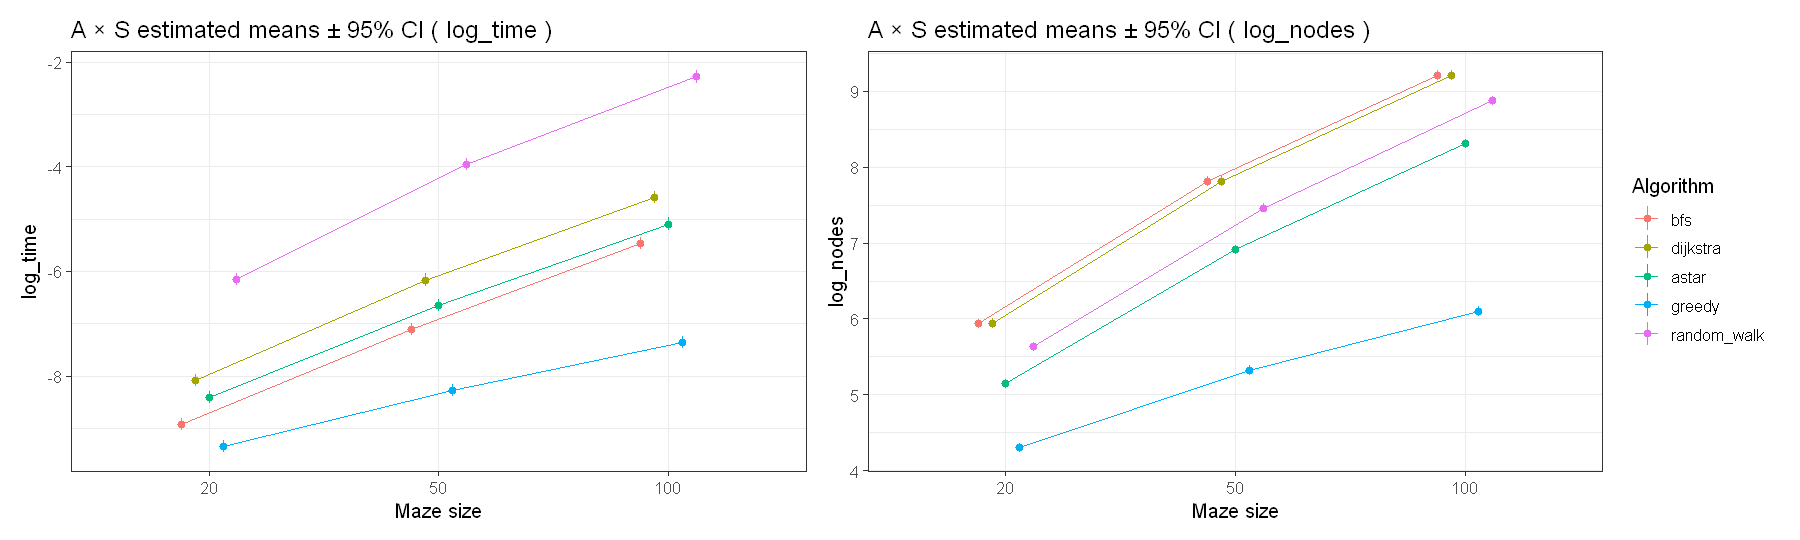

In [27]:
plots <- lapply(c("log_time", "log_nodes"), function(y)
  ggplot(cell_means(y), aes(level, mean_log, colour = A, group = A)) +
    geom_line(position = position_dodge(.3)) +
    geom_pointrange(aes(ymin = lo, ymax = hi), size = .3, position = position_dodge(.3)) +
    labs(x = "Maze size", y = y, title = paste("A × S estimated means ± 95% CI (", y, ")"), colour = "Algorithm"))
plots[[1]] + plots[[2]] + plot_layout(guides = "collect")

## 6. Diagnostics
- Subplot residuals (ε̂, from `lm(y ~ maze + A + A:S + A:D)`): residuals vs fitted by algorithm, normal Q-Q
- Whole-plot residuals (δ̂, maze effects from the maze-mean model): normal Q-Q

log_time : Levene across algorithms p = 1.63e-80 
        bfs    dijkstra       astar      greedy random_walk 
     0.2993      0.2634      0.4208      0.2997      0.7176 


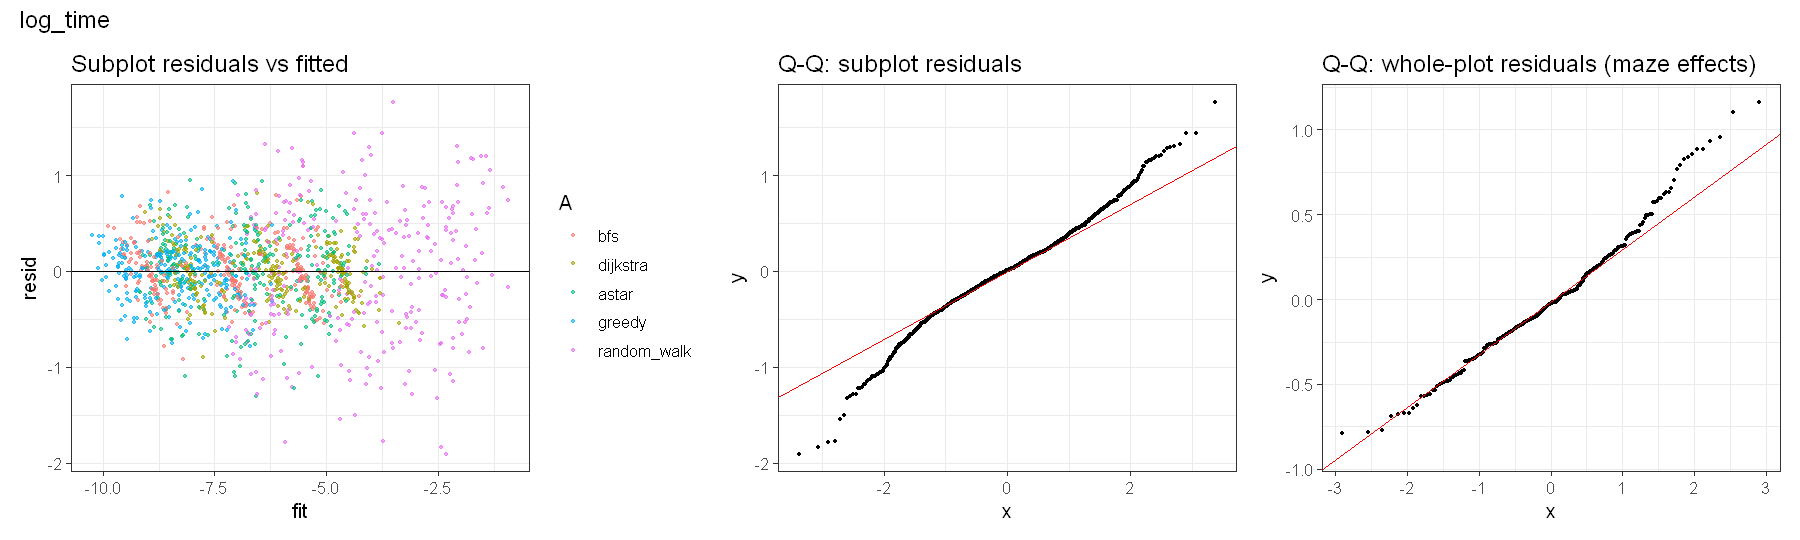

log_nodes : Levene across algorithms p = 6.07e-48 
        bfs    dijkstra       astar      greedy random_walk 
     0.1492      0.1499      0.3718      0.2156      0.3066 


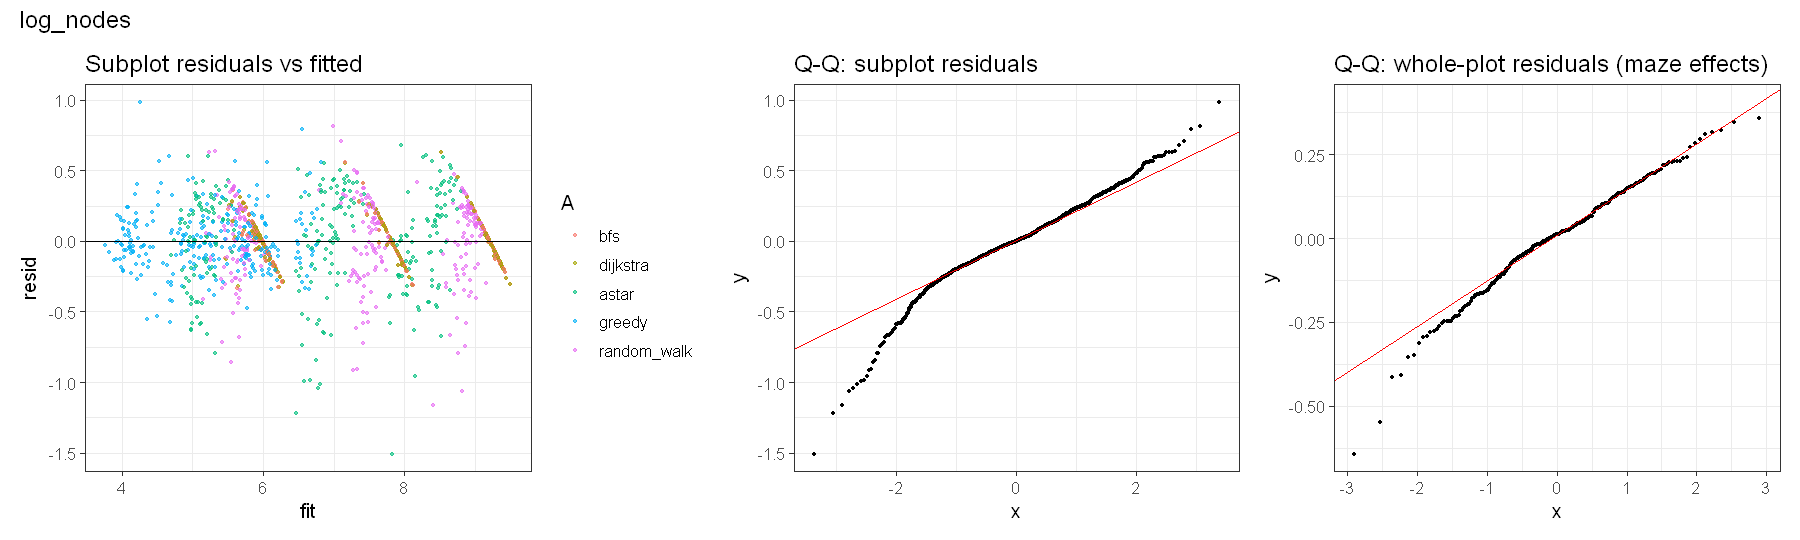

In [28]:
for (y in names(res)) {
  m_sp <- lm(as.formula(paste(y, "~ maze + A + A:S + A:D")), data = df)
  m_wp <- lm(as.formula(paste(y, "~ G + S*D")), data = wp)
  d <- df %>% mutate(fit = fitted(m_sp), resid = resid(m_sp))
  q1 <- ggplot(d, aes(fit, resid, colour = A)) + geom_point(size = .8, alpha = .6) + geom_hline(yintercept = 0) +
    labs(title = "Subplot residuals vs fitted")
  q2 <- ggplot(d, aes(sample = resid)) + stat_qq(size = .7) + stat_qq_line(colour = "red") +
    labs(title = "Q-Q: subplot residuals")
  q3 <- ggplot(data.frame(r = resid(m_wp)), aes(sample = r)) + stat_qq(size = .9) + stat_qq_line(colour = "red") +
    labs(title = "Q-Q: whole-plot residuals (maze effects)")
  print(q1 + q2 + q3 + plot_annotation(title = y))
  lev <- leveneTest(resid ~ A, data = d)
  cat(y, ": Levene across algorithms p =", format(lev$`Pr(>F)`[1], digits = 3), "\n")
  print(round(tapply(d$resid, d$A, sd), 4))
}

### Box-Cox check
Profile log-likelihood of λ for the full subplot model (maze + algorithm terms) on the raw response. λ ≈ 0 supports the log transform.

time_s: lambda_hat = -0.15, 95% CI [-0.16, -0.14]
nodes_explored: lambda_hat = 0.04, 95% CI [0.02, 0.07]


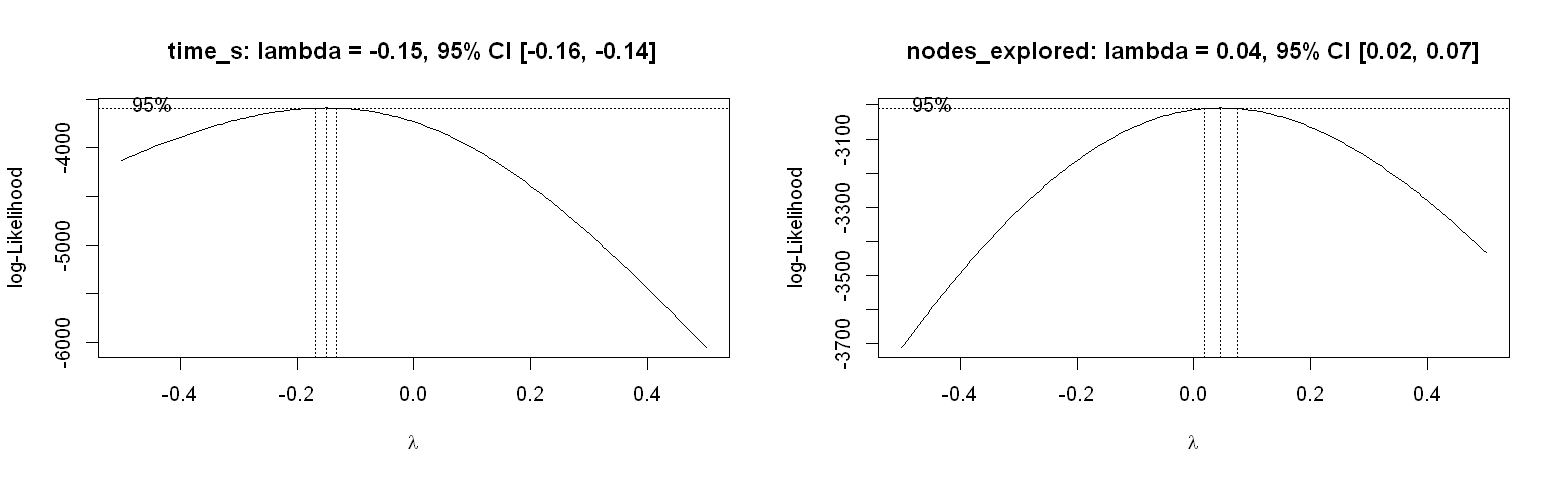

In [29]:
options(repr.plot.width = 13, repr.plot.height = 4)
par(mfrow = c(1, 2))
for (col in c("time_s", "nodes_explored")) {
  bc <- boxcox(as.formula(paste(col, "~ maze + A + A:S + A:D")), data = df,
               lambda = seq(-.5, .5, .005), plotit = TRUE)
  lam <- bc$x[which.max(bc$y)]; ci <- range(bc$x[bc$y > max(bc$y) - qchisq(.95, 1) / 2])
  title(sprintf("%s: lambda = %.2f, 95%% CI [%.2f, %.2f]", col, lam, ci[1], ci[2]))
  cat(sprintf("%s: lambda_hat = %.2f, 95%% CI [%.2f, %.2f]\n", col, lam, ci[1], ci[2]))
}
par(mfrow = c(1, 1)); options(repr.plot.width = 15, repr.plot.height = 4.5)

## 7. Extended subplot model (check the pooling assumption)
The proposal pools A×G and A×S×D into the error. Here they're fitted explicitly to see whether that pooling is reasonable.

In [30]:
for (y in names(res)) {
  t <- split_plot(df, y, sub = "A + A:S + A:D + A:G + A:S:D")$tab
  cat("\n", y, "\n"); print(t[t$Stratum == "Subplot", ], digits = 4)
}


 log_time 
   Stratum          Term   Df   Sum Sq  Mean Sq  F value    Pr(>F)   pct_SS
6  Subplot             A    4 2566.940 641.7349 2777.482 0.000e+00 46.71931
7  Subplot           S:A    8   95.043  11.8804   51.419 3.280e-70  1.72982
8  Subplot           D:A    8   40.294   5.0368   21.800 7.254e-31  0.73337
9  Subplot           G:A    8    8.582   1.0727    4.643 1.364e-05  0.15619
10 Subplot         S:D:A   16    5.128   0.3205    1.387 1.397e-01  0.09333
11 Subplot Subplot error 1036  239.367   0.2310       NA        NA  4.35657

 log_nodes 
   Stratum          Term   Df   Sum Sq   Mean Sq  F value     Pr(>F)   pct_SS
6  Subplot             A    4 1098.322 274.58042 3789.355  0.000e+00 33.31501
7  Subplot           S:A    8   75.325   9.41561  129.940 1.431e-150  2.28480
8  Subplot           D:A    8   24.426   3.05321   42.136  1.501e-58  0.74090
9  Subplot           G:A    8    9.181   1.14762   15.838  3.516e-22  0.27848
10 Subplot         S:D:A   16    2.753   0.17209    2

## 8. Sensitivity: drop the 4 censored random-walk mazes
The 4 mazes are removed entirely (all 5 runs) so every remaining maze still has all algorithms.

In [31]:
bad  <- unique(df$maze_id[df$success == 0])
df_s <- df %>% filter(!maze_id %in% bad) %>% droplevels()
for (y in c("log_time", "log_nodes")) {
  t <- split_plot(df_s, y)$tab
  cat("\n", y, "(mazes =", nlevels(df_s$maze), ")\n"); print(t[, c("Stratum", "Term", "Df", "F value", "Pr(>F)")], digits = 4)
}


 log_time (mazes = 266 )
     Stratum                           Term   Df  F value     Pr(>F)
1 Whole plot                      G (block)    2    1.326  2.674e-01
2 Whole plot                              S    2 1744.819 1.675e-149
3 Whole plot                              D    2   10.514  4.097e-05
4 Whole plot                            S:D    4    2.168  7.305e-02
5 Whole plot Whole-plot error [maze(G,S,D)]  255       NA         NA
6    Subplot                              A    4 2637.775  0.000e+00
7    Subplot                            S:A    8   48.265  2.176e-66
8    Subplot                            D:A    8   18.775  1.671e-26
9    Subplot                  Subplot error 1044       NA         NA

 log_nodes (mazes = 266 )
     Stratum                           Term   Df  F value     Pr(>F)
1 Whole plot                      G (block)    2    3.876  2.196e-02
2 Whole plot                              S    2 7999.956 8.577e-231
3 Whole plot                              D    2  

## 9. Conclusions

**Whole plot (maze level)**
- **Size dominates**: it's the largest single source of variation (≈43% of total SS for log time, ≈60% for log nodes). Both linear and quadratic size trends are significant (the quadratic term appears because the size levels 20/50/100 are unevenly spaced, and cost grows roughly with the number of cells).
- **Loop density** has a small but real effect: more loops mean fewer nodes and less time. The trend is purely linear (quadratic p ≈ 0.7–0.96).
- **S × D** is significant but tiny (≈0.1% SS). For time it drops to p ≈ 0.07 once the 4 censored mazes are removed, so treat it as weak.
- **Generation method (block)** doesn't matter for time (p = 0.21). For nodes it is significant (p < 0.001, Prim's mazes slightly cheaper), but its share of SS is < 0.1%, so blocking bought little.
- Maze-to-maze noise is small: ICC ≈ 0.25 (time), 0.08 (nodes).

**Subplot (algorithm within maze)**
- **Algorithm** is the other dominant factor (≈47% SS time, ≈33% nodes).
- Planned contrasts (ratio of geometric means, all p < 0.001):
  - A* vs Dijkstra: A* explores ~0.42× the nodes and takes ~0.64× the time.
  - Informed vs uninformed: ~0.19× the nodes, ~0.45× the time.
  - Random walk vs rest: ~1.6× the nodes but **~20× the time**, because it revisits cells many times (steps ≫ unique nodes).
- **A × S and A × D are significant**: the informed advantage *grows* with size (nodes ratio 0.30 → 0.14 from 20×20 to 100×100) and with loop density (0.27 → 0.14). So maze structure changes **how much** better an algorithm is.
- It does **not** change **which** algorithm wins: Greedy best-first is fastest and explores the fewest nodes in nearly every maze (87–100% per cell). Its paths are longer than optimal, though (see Section 2), so it trades optimality for speed. Among the optimal methods, A* beats BFS/Dijkstra on nodes everywhere. BFS beats Dijkstra on time (same nodes, less overhead).

**Model checks**
- Box-Cox: λ̂ = −0.15 (time) and 0.05 (nodes). The 95% CIs technically exclude 0 because n = 1350 makes them very narrow, but both are close to 0, so the log stays the practical choice (and keeps the ratio interpretation). λ = −0.15 for time could be tried as a robustness check.
- Residual variance is **not** equal across algorithms (Levene p < 1e-40; random walk and A* are the noisiest). The F tests for A are so large that this won't change conclusions, but the contrast SEs that involve random walk are probably too small. Weighted LS or separate variances per algorithm would be the fix if needed.
- Pooling assumption: A×S×D is negligible for time (p = 0.14) but significant for nodes (p = 0.002, 0.08% SS). A×G is significant for both but small (0.16–0.28% SS). Pooling is fine in practice, but report it.
- Dropping the 4 censored random-walk mazes leaves every conclusion unchanged except S×D for time.